# 03 - Exploratory data analysis

Which issues drive demand, which groups have the longest recorded delays, and how does demand change over time?

Count all tickets for demand. For delay summaries, use nonnegative, recorded wall-clock durations and show outcome coverage alongside the results. Compare key estimates after excluding inconsistencies that directly concern resolution. The 24-hour label will be decided in the feature engineering step.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

cwd = Path.cwd().resolve()
project = next(
    folder for folder in (cwd, *cwd.parents)
    if (folder / "src" / "preprocessing.py").is_file()
)
tickets = pd.read_parquet(project / "data" / "processed" / "tickets.parquet")
figures = project / "reports" / "figures"
figures.mkdir(parents=True, exist_ok=True)
duration = "resolution_wallclock_hours"
observed = tickets[duration].notna() & tickets[duration].ge(0)
resolution_flags = [
    "flag_first_resolution_before_creation", "flag_final_resolution_before_creation",
    "flag_final_resolution_before_first", "flag_wallclock_timestamp_mismatch",
]
consistent = observed & ~tickets[resolution_flags].any(axis=1)
analysis = tickets.assign(
    recorded_hours=tickets[duration].where(observed),
    consistent_hours=tickets[duration].where(consistent),
)

def group_summary(column):
    groups = analysis.groupby(column, observed=True, dropna=False)
    result = groups.agg(
        tickets=("ticket_id", "size"),
        recorded=("recorded_hours", "count"),
        median_hours=("recorded_hours", "median"),
        p90_hours=("recorded_hours", lambda hours: hours.quantile(.90)),
        consistent_median=("consistent_hours", "median"),
    )
    return result.assign(recorded_pct=100 * result["recorded"] / result["tickets"])

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(figures / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## Demand and delays by category

Ticket count measures support demand. Median delay describes a typical observed case; the 90th percentile describes the slower end of the distribution. Read outcome coverage before comparing segments.

,tickets,recorded,median_hours,p90_hours,consistent_median,recorded_pct
category,,,,,,
Refunds,10723,9692,69.62,336.0,68.07,90.39
Billing,10496,9421,25.65,252.4,25.01,89.76
Account Management,10152,9116,19.48,277.88,18.9,89.8
Onboarding & How-To,10131,9134,16.88,221.19,16.57,90.16
Authentication & Access,9127,8170,18.42,218.23,18.07,89.51
Security,9095,8168,65.49,336.64,64.55,89.81
Bugs & Errors,8600,7750,41.16,321.21,40.18,90.12
Integrations & API,8587,7717,21.18,195.47,20.53,89.87
Data Sync,8497,7623,33.67,307.36,32.67,89.71


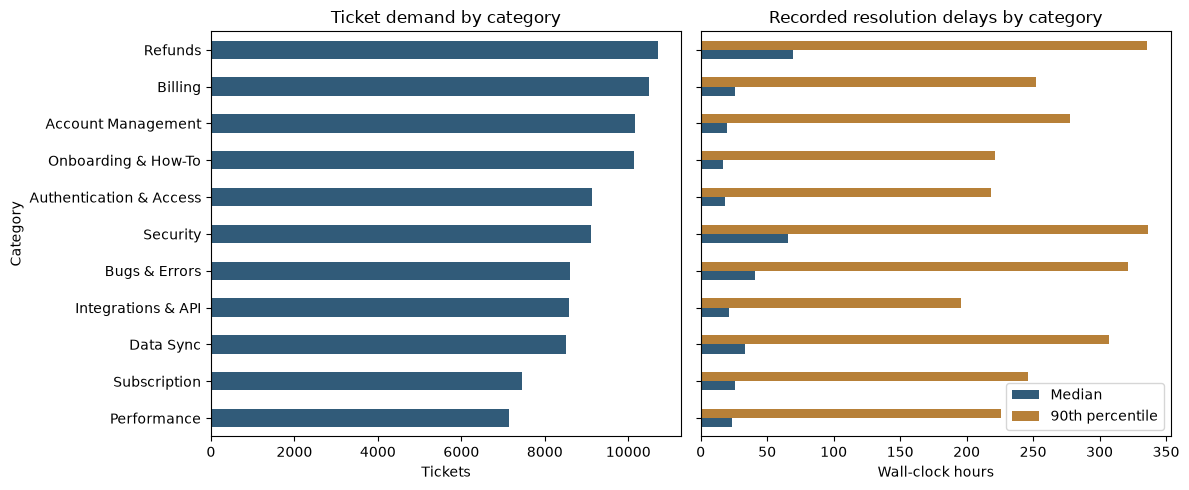

In [2]:
categories = group_summary("category").sort_values("tickets", ascending=False)
display(categories.round(2))
ordered = categories.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
ordered["tickets"].plot.barh(ax=axes[0], color="#315b79")
ordered[["median_hours", "p90_hours"]].rename(
    columns={"median_hours": "Median", "p90_hours": "90th percentile"}
).plot.barh(ax=axes[1], color=["#315b79", "#b78038"])
axes[0].set(title="Ticket demand by category", xlabel="Tickets", ylabel="Category")
axes[1].set(title="Recorded resolution delays by category", xlabel="Wall-clock hours")
save_figure(fig, "category_demand_and_delay")

**Business takeaway.** Refunds produced the most tickets (10,723). Refunds had the highest median recorded delay (69.62 hours). Use both volume and delay to decide which queues to review.

## Priority and resolution

Use a boxplot to compare the center and spread of observed delays. A logarithmic axis makes short and long cases readable together. Boxplot points outside the whiskers are hidden for readability and still contribute to the group summaries. Priority differences describe an association and can reflect routing or a different mix of issues.

,tickets,recorded,median_hours,p90_hours,consistent_median,recorded_pct
priority,,,,,,
Low,28521,25627,18.65,274.29,17.97,89.85
Medium,33417,30068,34.53,325.18,33.42,89.98
High,26319,23679,39.57,312.29,38.33,89.97
Urgent,11743,10558,27.92,262.38,27.26,89.91


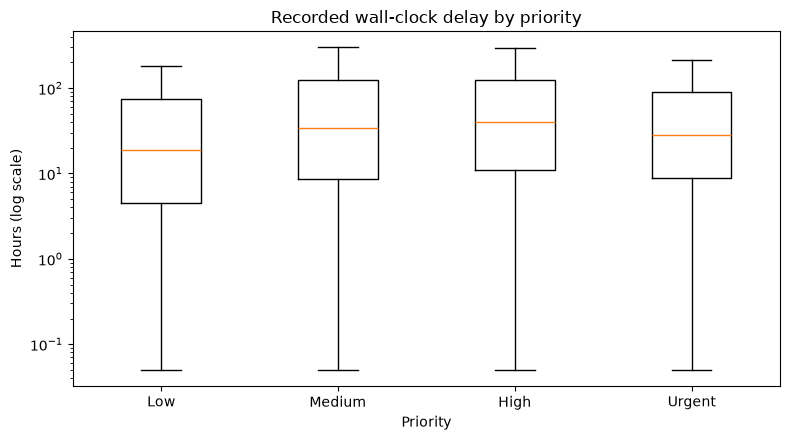

In [3]:
priorities = group_summary("priority").reindex(["Low", "Medium", "High", "Urgent"])
display(priorities.round(2))
samples = [
    analysis.loc[analysis["priority"].eq(priority) & analysis["recorded_hours"].gt(0),
                 "recorded_hours"].dropna().to_numpy(dtype=float)
    for priority in priorities.index
]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(samples, tick_labels=priorities.index, showfliers=False)
ax.set(yscale="log", title="Recorded wall-clock delay by priority",
       xlabel="Priority", ylabel="Hours (log scale)")
save_figure(fig, "priority_resolution_boxplot")

**Business takeaway.** High priority had the longest median delay (39.57 hours), while Medium had the highest 90th percentile (325.18 hours). Urgent tickets had a lower median than High tickets. Compare issue mix and routing before attributing these differences to priority.

## Support teams and issue types

Assigned team measures workload received by support teams. The CSV has no requester department. Rank issue types by median delay and require at least 100 recorded outcomes for this comparison so the chart focuses on recurring issues.

,tickets,recorded,median_hours,p90_hours,consistent_median,recorded_pct
assigned_team,,,,,,
Tier 1 Support,35461,31960,17.45,214.92,17.23,90.13
Engineering,23540,21171,24.97,291.88,24.23,89.94
Billing,18937,17053,41.02,324.14,40.07,90.05
Tier 2 Support,14089,12594,57.47,325.28,55.7,89.39
Security,7973,7154,63.76,336.18,62.36,89.73


,tickets,recorded,median_hours,p90_hours,consistent_median,recorded_pct
issue_type_id,,,,,,
security_gdpr_data_request,1619,1462,303.06,392.55,299.45,90.3
security_delete_my_data,840,746,291.02,404.85,289.12,88.81
account_region_change,537,469,231.97,392.98,230.76,87.34
refunds_chargeback_question,1426,1277,182.72,366.22,180.11,89.55
bugs_intermittent_error,1218,1079,181.03,363.84,177.5,88.59
refunds_refund_denied_appeal,1085,974,176.92,375.42,175.58,89.77
data_data_corruption,1466,1335,172.78,366.58,169.88,91.06
security_data_breach_concern,674,617,172.25,361.26,170.0,91.54
account_merge_accounts,1054,946,171.52,349.82,169.78,89.75


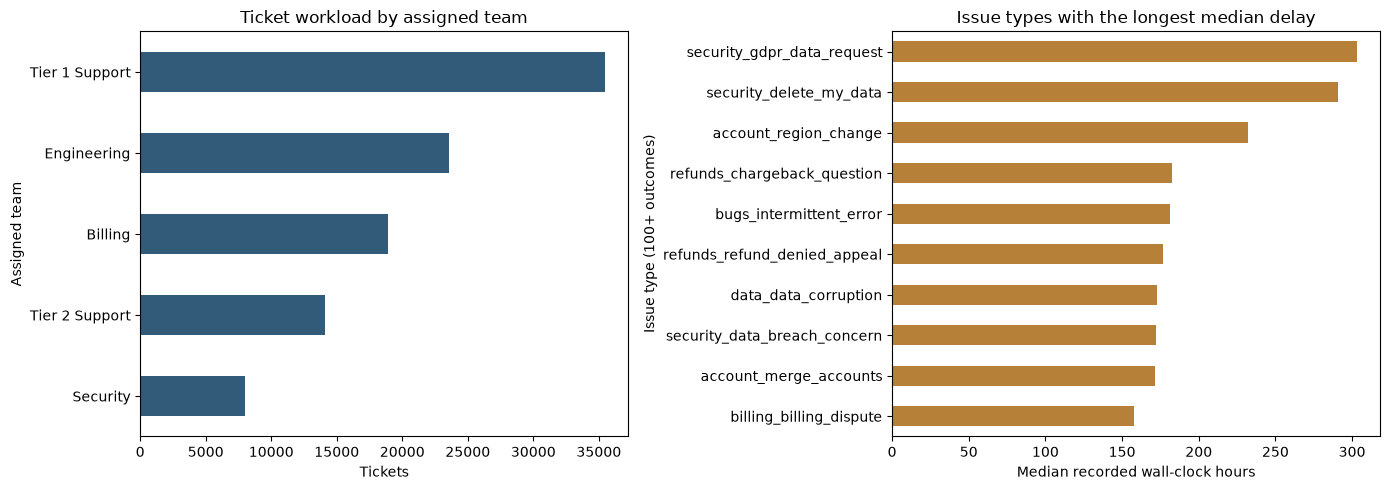

In [4]:
teams = group_summary("assigned_team").sort_values("tickets", ascending=False)
display(teams.round(2))
issue_types = group_summary("issue_type_id")
slow_types = issue_types.loc[issue_types["recorded"].ge(100)].nlargest(10, "median_hours")
display(slow_types.round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
teams["tickets"].iloc[::-1].plot.barh(ax=axes[0], color="#315b79")
slow_types["median_hours"].iloc[::-1].plot.barh(ax=axes[1], color="#b78038")
axes[0].set(title="Ticket workload by assigned team", xlabel="Tickets", ylabel="Assigned team")
axes[1].set(title="Issue types with the longest median delay",
            xlabel="Median recorded wall-clock hours", ylabel="Issue type (100+ outcomes)")
save_figure(fig, "team_workload_and_issue_delays")

**Business takeaway.** Tier 1 Support received 35,461 tickets. Security's median delay was 63.76 hours, and its GDPR data requests had the longest issue-type median (303.06 hours across 1,462 recorded outcomes). Review these cases for opportunities to reduce delays.

## Trends by creation month

Group tickets by the month they were opened. The resolution line describes recorded outcomes for each creation cohort. Check coverage before interpreting changes near the end of the dataset, when there may have been less time to observe outcomes.

,tickets,recorded_pct,median_hours
creation_month,,,
2022-01-01,1906,92.5,26.83
2022-02-01,1942,90.73,30.22
2022-03-01,2240,91.34,27.59
2022-04-01,2077,91.72,34.33
2022-05-01,2104,91.21,28.87
2022-06-01,2140,91.03,28.98
2022-07-01,1991,90.01,31.65
2022-08-01,2034,91.64,32.77
2022-09-01,1902,92.32,30.48


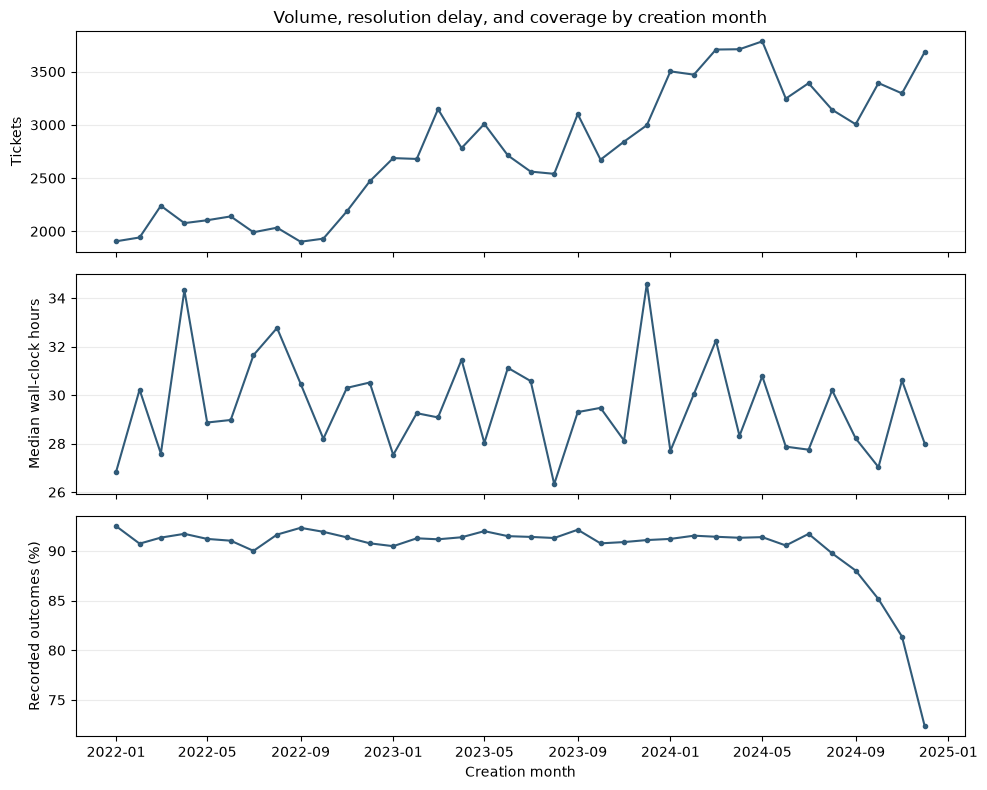

In [5]:
analysis["creation_month"] = analysis["created_at"].dt.to_period("M").dt.to_timestamp()
monthly = group_summary("creation_month").sort_index()
display(monthly[["tickets", "recorded_pct", "median_hours"]].round(2))
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, column, label in zip(
    axes, ["tickets", "median_hours", "recorded_pct"],
    ["Tickets", "Median wall-clock hours", "Recorded outcomes (%)"],
):
    ax.plot(monthly.index, monthly[column], color="#315b79", marker=".", linewidth=1.5)
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=.25)
axes[0].set_title("Volume, resolution delay, and coverage by creation month")
axes[-1].set_xlabel("Creation month")
save_figure(fig, "monthly_ticket_trends")

**Business takeaway.** Yearly intake rose from 24,924 in 2022 to 41,341 in 2024. May 2024 was the busiest month (3,785 tickets). Outcome coverage was lowest in 2024-12 (72.3%), so use care when comparing its median delay with earlier cohorts.

## Overall delay distribution and data quality sensitivity

Use log-spaced histogram bins for positive durations so the main distribution and long tail are visible together. Compare the median and 90th percentile with and without time or duration inconsistencies. The comparison applies only to this descriptive analysis.

,tickets,median_hours,p90_hours
All recorded nonnegative outcomes,89932.0,29.33,308.29
Resolution consistency checks passed,87981.0,28.43,290.62


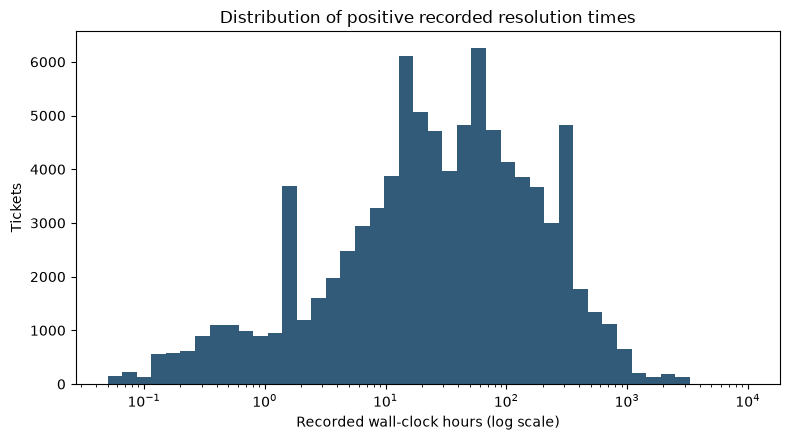

In [6]:
populations = {
    "All recorded nonnegative outcomes": analysis["recorded_hours"].dropna(),
    "Resolution consistency checks passed": analysis["consistent_hours"].dropna(),
}
sensitivity = pd.DataFrame({
    name: {"tickets": len(hours), "median_hours": hours.median(),
           "p90_hours": hours.quantile(.90)}
    for name, hours in populations.items()
}).T
display(sensitivity.round(2))
positive = analysis.loc[analysis["recorded_hours"].gt(0), "recorded_hours"]
import numpy as np

bins = np.geomspace(float(positive.min()), float(positive.max()), 45)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(positive.to_numpy(dtype=float), bins=bins, color="#315b79")
ax.set(xscale="log", xlabel="Recorded wall-clock hours (log scale)", ylabel="Tickets",
       title="Distribution of positive recorded resolution times")
save_figure(fig, "resolution_time_distribution")

**Business takeaway.** Across recorded outcomes, the median was 29.33 hours and the 90th percentile was 308.29 hours. Filtering the resolution consistency flags for this comparison moved those estimates to 28.43 and 290.62 hours. Monitor the tail alongside the median, since the tail is more affected by the data quality filter.